# 04 · My annotation vs. the original publications

The authors' labels enter the project for the first time here. They are an independent expert annotation of the same cells:

- **Xenium:** Janesick et al., *Nat Commun* 2023, sheet "Xenium R1 Fig1-5 (supervised)".
- **CODEX:** Schürch et al., *Cell* 2020, column `ClusterName`, plus their `neighborhood name`.

**Questions**

1. **Name mapping.** How do my types correspond to theirs? The granularity differs, so the mapping is written out explicitly.
2. **Cell-level agreement.** Confusion matrix, adjusted Rand index (ARI) and agreement per type.
3. **Composition.** How do my cell-type proportions compare with theirs?
4. **QC.** Are the cells I removed the ones they call debris?
5. **Main findings.** Do my labels reproduce the papers' key observations?
6. **KDE link.** Are the cells flagged in notebook 03 concentrated where we disagree?

## Parameters

In [1]:
from pathlib import Path

XE_LABELS   = Path("data/xenium_breast/Cell_Barcode_Type_Matrices.xlsx")
XE_SHEET    = "Xenium R1 Fig1-5 (supervised)"
CX_FILE     = Path("data/codex_crc/CRC_clusters_neighborhoods_markers.csv")
RESULTS_DIR = Path("results")
FIG_DIR     = RESULTS_DIR / "figures"
AGG_MIN     = 0.5      # CODEX: a B cell is "in an aggregate" if >= this fraction of its neighbors are B cells
SEED        = 0

In [2]:
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import fisher_exact, mannwhitneyu
from sklearn.metrics import adjusted_rand_score

FIG_DIR.mkdir(parents=True, exist_ok=True)
FLAGS = ["confirmed", "outlier", "fits another type"]


In [3]:
# record the software versions of this run (a fixed seed alone does not guarantee identical results across versions)
import sys
from importlib.metadata import version
print("python", sys.version.split()[0])
print({p: version(p) for p in ["numpy", "pandas", "scipy", "scikit-learn", "scanpy", "anndata",
                                "squidpy", "igraph", "leidenalg", "matplotlib"]})

python 3.13.17
{'numpy': '2.4.6', 'pandas': '3.0.5', 'scipy': '1.18.1', 'scikit-learn': '1.9.1', 'scanpy': '1.12.4', 'anndata': '0.13.4', 'squidpy': '1.8.3', 'igraph': '1.0.0', 'leidenalg': '0.12.0', 'matplotlib': '3.11.2'}


### Helpers used for both datasets

In [4]:
def valid_assigned_mask(mine, theirs):
    """Cells with mapped, non-missing labels on both sides and neither side unassigned."""
    mine = np.asarray(mine, dtype=object)
    theirs = np.asarray(theirs, dtype=object)
    missing = pd.isna(mine) | pd.isna(theirs)
    return (~missing) & (mine != "unassigned") & (theirs != "unassigned")

def agreement_tables(mine, theirs):
    # Exclude missing/unmapped and explicitly unassigned labels from agreement metrics.
    mine = np.asarray(mine, dtype=object)
    theirs = np.asarray(theirs, dtype=object)
    both = valid_assigned_mask(mine, theirs)
    m, t = mine[both], theirs[both]
    if len(m) == 0:
        raise ValueError("No cells have mapped, assigned labels on both sides.")
    rows = []
    for c in sorted(set(m) | set(t)):
        rows.append({"type": c,
                     "my cells": int((m == c).sum()),
                     "their cells": int((t == c).sum()),
                     "% of mine they agree with": 100 * (t[m == c] == c).mean() if (m == c).any() else np.nan,
                     "% of theirs I recover": 100 * (m[t == c] == c).mean() if (t == c).any() else np.nan})
    return pd.DataFrame(rows).set_index("type").round(1), 100 * (m == t).mean()

def plot_confusion(mine, theirs, order_rows, order_cols, title, ax):
    # Row-normalized among cells with a mapped label on both sides.
    mine = np.asarray(mine, dtype=object)
    theirs = np.asarray(theirs, dtype=object)
    valid = ~pd.isna(mine) & ~pd.isna(theirs)
    ct = pd.crosstab(pd.Series(mine[valid], name="mine"), pd.Series(theirs[valid], name="theirs"), normalize="index") * 100
    ct = ct.reindex(index=[r for r in order_rows if r in ct.index], columns=[c for c in order_cols if c in ct.columns], fill_value=0)
    im = ax.imshow(ct.values, cmap="Blues", vmin=0, vmax=100, aspect="auto")
    ax.set_xticks(range(ct.shape[1]), ct.columns, rotation=70, ha="right", fontsize=9)
    ax.set_yticks(range(ct.shape[0]), ct.index, fontsize=9)
    for i in range(ct.shape[0]):
        for j in range(ct.shape[1]):
            if ct.values[i, j] >= 10:
                ax.text(j, i, f"{ct.values[i, j]:.0f}", ha="center", va="center", fontsize=7,
                        color="white" if ct.values[i, j] > 60 else "black")
    ax.set(xlabel="authors' label", ylabel="my label", title=title)
    return im

def plot_composition(mine, theirs, order, title, ax):
    # Composition includes unassigned cells; NaN labels are counted separately in coverage diagnostics.
    pm = pd.Series(mine).value_counts(normalize=True).reindex(order, fill_value=0) * 100
    pt = pd.Series(theirs).value_counts(normalize=True).reindex(order, fill_value=0) * 100
    x = np.arange(len(order)); w = 0.4
    ax.bar(x - w / 2, pm, w, label="mine", color="#4c72b0"); ax.bar(x + w / 2, pt, w, label="authors", color="#dd8452")
    ax.set_xticks(x, order, rotation=60, ha="right"); ax.set(ylabel="% of all cells", title=title); ax.legend()

def kde_link(kde, mine_common, theirs_common, competitor_common):
    # Require aligned arrays; exclude missing/unmapped and unassigned annotations.
    mine_common = np.asarray(mine_common, dtype=object)
    theirs_common = np.asarray(theirs_common, dtype=object)
    competitor_common = np.asarray(competitor_common, dtype=object)
    flags = kde["flag"].to_numpy()
    if not (len(flags) == len(mine_common) == len(theirs_common) == len(competitor_common)):
        raise ValueError("KDE flags and annotation arrays are not aligned or have different lengths.")
    ok = valid_assigned_mask(mine_common, theirs_common) & ~pd.isna(flags)
    d = pd.DataFrame({"flag": flags[ok],
                      "disagree": (mine_common != theirs_common)[ok],
                      "competitor_matches_authors": (competitor_common == theirs_common)[ok]})
    d = d[d["flag"].isin(FLAGS)]
    if d.empty:
        raise ValueError("No valid cells remain for KDE-versus-author comparison.")
    rate = d.groupby("flag", observed=True)["disagree"].agg(["size", "mean"]).reindex(FLAGS)
    rate.columns = ["cells", "% disagree with authors"]; rate["% disagree with authors"] *= 100
    flagged = d["flag"] != "confirmed"
    table = [[int((flagged & d.disagree).sum()), int((flagged & ~d.disagree).sum())],
             [int((~flagged & d.disagree).sum()), int((~flagged & ~d.disagree).sum())]]
    odds, p = fisher_exact(table)
    mis_dis = d[(d.flag == "fits another type") & d.disagree]
    comp_match = 100 * mis_dis["competitor_matches_authors"].mean() if len(mis_dis) else np.nan
    return rate.round(1), odds, p, comp_match, len(mis_dis)


def bh_adjust(pvalues):
    """Benjamini-Hochberg FDR-adjusted p-values; preserves NaNs."""
    p = np.asarray(pvalues, dtype=float)
    q = np.full(p.shape, np.nan, dtype=float)
    valid = np.isfinite(p)
    pv = p[valid]
    if pv.size:
        order = np.argsort(pv)
        ranked = pv[order]
        adj = ranked * pv.size / np.arange(1, pv.size + 1)
        adj = np.minimum.accumulate(adj[::-1])[::-1]
        restored = np.empty_like(adj)
        restored[order] = np.minimum(adj, 1.0)
        q[valid] = restored
    return q



def mantel_haenszel_or(flag, disagree, strata):
    """Odds ratio of (flagged, disagreeing) pooled over strata (Mantel-Haenszel).

    Stratifying by my cell type removes confounding by type composition: both the flag rate
    and the disagreement rate differ strongly between types.
    """
    d = pd.DataFrame({"f": np.asarray(flag, bool), "x": np.asarray(disagree, bool), "s": np.asarray(strata)})
    num = den = 0.0
    for _, g in d.groupby("s"):
        n = len(g)
        a = (g.f & g.x).sum(); b = (g.f & ~g.x).sum(); c = (~g.f & g.x).sum(); e = (~g.f & ~g.x).sum()
        num += a * e / n; den += b * c / n
    return num / den if den > 0 else np.nan


def patient_level_link(flag, disagree, patient, min_cells=20):
    """Per patient: disagreement rate among flagged minus among confirmed cells; Wilcoxon signed-rank across patients.

    Patients with fewer than `min_cells` flagged or confirmed (eligible) cells are left out and counted.
    """
    from scipy.stats import wilcoxon
    d = pd.DataFrame({"f": np.asarray(flag, bool), "x": np.asarray(disagree, bool), "p": np.asarray(patient)})
    counts = d.groupby(["p", "f"]).size().unstack().reindex(columns=[False, True]).fillna(0)
    rates = d.groupby(["p", "f"])["x"].mean().unstack().reindex(columns=[False, True])
    rates.columns = ["confirmed", "flagged"]; counts.columns = ["confirmed", "flagged"]
    keep = (counts["confirmed"] >= min_cells) & (counts["flagged"] >= min_cells)
    n_dropped = int((~keep).sum())
    rates = rates[keep]
    diff = (rates["flagged"] - rates["confirmed"]) * 100
    p = wilcoxon(diff).pvalue if len(diff) >= 5 else np.nan
    return rates.mul(100).round(1), diff, p, n_dropped


## Part A · Xenium breast cancer

### A1 · Name mapping

The two annotations name types at different granularity. Both are mapped onto a common vocabulary, written here from
the **names and marker evidence alone**, before looking at the agreement.

- **DCIS:** both annotations split DCIS into two groups numbered 1 and 2. The numbering is arbitrary in each, so both map to one `DCIS` class.
- **Stromal:** the authors have a single "Stromal" class. My fibroblast, CAF and adipocyte types map to it.
- **No counterpart:** the authors have no NK or plasma-cell class. NK cells join CD8+ T cells, and plasma cells join B cells.
- **DCs:** LAMP3+ DCs are mature DCs, and IRF7+ DCs are pDCs (IRF7 is the pDC master regulator).
- **Unassigned:** the authors' "Unlabeled" and the two "Hybrid" classes, and my `unknown`.

In [5]:
XE_MINE = {
    "Invasive tumor": "Invasive tumor", "Proliferating invasive tumor": "Proliferating invasive tumor",
    "DCIS 1": "DCIS", "DCIS 2": "DCIS",
    "Myoepithelial": "Myoepithelial", "Myoepithelial KRT15+": "Myoepithelial KRT15+",
    "CAF / myofibroblasts": "Stromal", "Fibroblasts": "Stromal", "Adipocytes": "Stromal",
    "Perivascular": "Perivascular", "Endothelial": "Endothelial",
    "CD4+ T cells": "CD4+ T", "CD8+ T cells": "CD8+ T / NK", "NK cells": "CD8+ T / NK",
    "B cells": "B / plasma", "Plasma cells": "B / plasma",
    "Macrophages APOC1+": "Macrophages", "Macrophages CD163+": "Macrophages",
    "Mature DCs": "Mature DCs", "pDCs": "pDCs", "Mast cells": "Mast cells", "unknown": "unassigned",
}
XE_AUTH = {
    "Invasive_Tumor": "Invasive tumor", "Prolif_Invasive_Tumor": "Proliferating invasive tumor",
    "DCIS_1": "DCIS", "DCIS_2": "DCIS",
    "Myoepi_ACTA2+": "Myoepithelial", "Myoepi_KRT15+": "Myoepithelial KRT15+",
    "Stromal": "Stromal", "Perivascular-Like": "Perivascular", "Endothelial": "Endothelial",
    "CD4+_T_Cells": "CD4+ T", "CD8+_T_Cells": "CD8+ T / NK", "B_Cells": "B / plasma",
    "Macrophages_1": "Macrophages", "Macrophages_2": "Macrophages",
    "LAMP3+_DCs": "Mature DCs", "IRF7+_DCs": "pDCs", "Mast_Cells": "Mast cells",
    "Unlabeled": "unassigned", "Stromal_&_T_Cell_Hybrid": "unassigned", "T_Cell_&_Tumor_Hybrid": "unassigned",
}
XE_ORDER = ["Invasive tumor", "Proliferating invasive tumor", "DCIS", "Myoepithelial", "Myoepithelial KRT15+",
            "Stromal", "Perivascular", "Endothelial", "CD4+ T", "CD8+ T / NK", "B / plasma", "Macrophages",
            "Mature DCs", "pDCs", "Mast cells", "unassigned"]

pd.DataFrame({"common type": XE_ORDER,
              "my types": [", ".join(k for k, v in XE_MINE.items() if v == c) for c in XE_ORDER],
              "authors' types": [", ".join(k for k, v in XE_AUTH.items() if v == c) for c in XE_ORDER]}).set_index("common type")

,my types,authors' types
common type,,
Invasive tumor,Invasive tumor,Invasive_Tumor
Proliferating invasive tumor,Proliferating invasive tumor,Prolif_Invasive_Tumor
DCIS,"DCIS 1, DCIS 2","DCIS_1, DCIS_2"
Myoepithelial,Myoepithelial,Myoepi_ACTA2+
Myoepithelial KRT15+,Myoepithelial KRT15+,Myoepi_KRT15+
Stromal,"CAF / myofibroblasts, Fibroblasts, Adipocytes",Stromal
Perivascular,Perivascular,Perivascular-Like
Endothelial,Endothelial,Endothelial
CD4+ T,CD4+ T cells,CD4+_T_Cells


In [6]:
xe = sc.read_h5ad(RESULTS_DIR / "xenium_annotated.h5ad")
auth_all = pd.read_excel(XE_LABELS, sheet_name=XE_SHEET)
auth_all["Barcode"] = auth_all["Barcode"].astype(str)
if auth_all["Barcode"].duplicated().any():
    raise ValueError("Xenium author-label spreadsheet contains duplicate Barcodes.")
auth_all = auth_all.set_index("Barcode")["Cluster"]
if not xe.obs_names.is_unique:
    raise ValueError("Xenium AnnData obs_names are not unique.")
if not set(auth_all.dropna().unique()).issubset(XE_AUTH):
    raise ValueError(f"Unmapped Xenium author labels: {sorted(set(auth_all.dropna().unique()) - set(XE_AUTH))}")
assert set(XE_AUTH) == set(auth_all.unique()), "unmapped author label"

xe.obs["authors"] = auth_all.reindex(xe.obs_names).values
xe.obs["mine_common"] = xe.obs["cell_type"].astype(str).map(XE_MINE)
xe.obs["auth_common"] = xe.obs["authors"].map(XE_AUTH)
if xe.obs["mine_common"].isna().any():
    missing = sorted(xe.obs.loc[xe.obs["mine_common"].isna(), "cell_type"].astype(str).unique())
    raise ValueError(f"Unmapped Xenium labels in XE_MINE: {missing}")
print(f"{xe.n_obs:,} cells; authors' label found for {xe.obs['authors'].notna().mean():.1%}")

164,000 cells; authors' label found for 100.0%


### A2 · Cell-level agreement

In [7]:
mine_xe, auth_xe = xe.obs["mine_common"].to_numpy(dtype=object), xe.obs["auth_common"].to_numpy(dtype=object)
valid_xe = valid_assigned_mask(mine_xe, auth_xe)
if valid_xe.sum() == 0:
    raise ValueError("No Xenium cells have mapped, assigned labels on both sides.")
ari_common = adjusted_rand_score(auth_xe[valid_xe], mine_xe[valid_xe])
fine_valid_xe = xe.obs["authors"].notna().to_numpy() & xe.obs["cell_type"].notna().to_numpy()
ari_fine = adjusted_rand_score(xe.obs.loc[fine_valid_xe, "authors"].astype(str),
                               xe.obs.loc[fine_valid_xe, "cell_type"].astype(str))
tab_xe, acc_xe = agreement_tables(mine_xe, auth_xe)
print(f"Cells with mapped, assigned labels on both sides: {valid_xe.sum():,}/{xe.n_obs:,} ({valid_xe.mean():.1%})")
print(f"ARI (common vocabulary, assigned cells): {ari_common:.3f}   ARI (original labels, non-missing cells): {ari_fine:.3f}")
print(f"agreement on cells both annotations assign: {acc_xe:.1f}%")
allc = ~pd.isna(mine_xe) & ~pd.isna(auth_xe)
print(f"with 'unassigned' kept as a category (all {allc.sum():,} cells): ARI {adjusted_rand_score(auth_xe[allc], mine_xe[allc]):.3f}, "
      f"same label {100 * (mine_xe[allc] == auth_xe[allc]).mean():.1f}%  |  excluded from the main metrics: {(~valid_xe).sum():,} cells")
tab_xe.reindex([c for c in XE_ORDER if c in tab_xe.index])

Cells with mapped, assigned labels on both sides: 154,493/164,000 (94.2%)
ARI (common vocabulary, assigned cells): 0.550   ARI (original labels, non-missing cells): 0.426
agreement on cells both annotations assign: 75.3%


with 'unassigned' kept as a category (all 164,000 cells): ARI 0.516, same label 71.3%  |  excluded from the main metrics: 9,507 cells


,my cells,their cells,% of mine they agree with,% of theirs I recover
type,,,,
Invasive tumor,23951,32550,99.5,73.2
Proliferating invasive tumor,7934,3774,46.3,97.3
DCIS,24886,23493,87.6,92.8
Myoepithelial,6105,7030,89.1,77.4
Myoepithelial KRT15+,3872,2849,71.5,97.2
Stromal,22631,41061,95.0,52.4
Perivascular,3510,839,22.7,95.1
Endothelial,8902,8927,84.1,83.9
CD4+ T,16221,8431,47.8,92.0


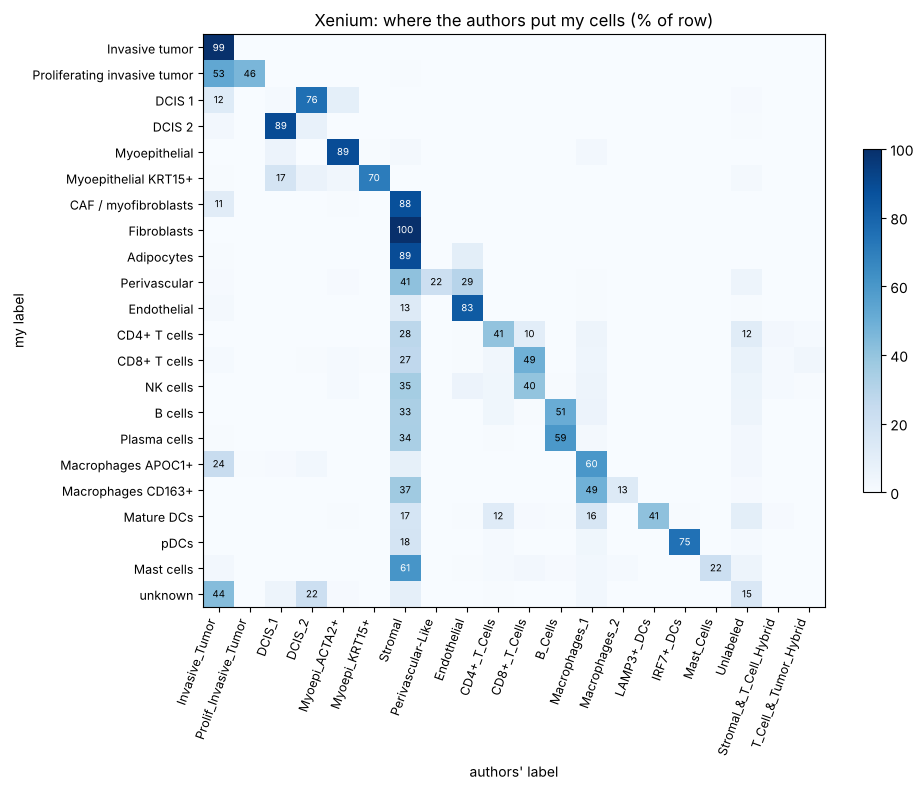

In [8]:
fig, ax = plt.subplots(figsize=(10, 8))
im = plot_confusion(xe.obs["cell_type"].astype(str).to_numpy(), xe.obs["authors"].to_numpy(),
                    list(XE_MINE), list(XE_AUTH), "Xenium: where the authors put my cells (% of row)", ax)
plt.colorbar(im, ax=ax, shrink=0.6)
plt.tight_layout(); plt.savefig(FIG_DIR / "xenium_confusion.png", dpi=120); plt.show()

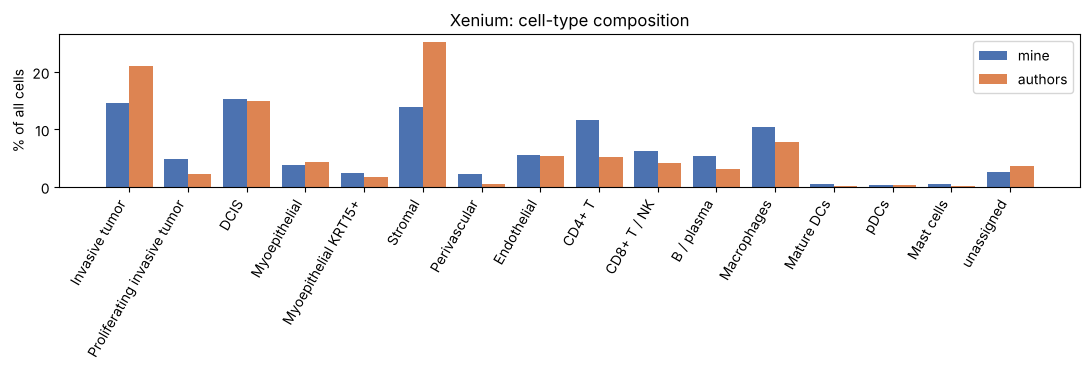

In [9]:
fig, ax = plt.subplots(figsize=(11, 3.8))
plot_composition(mine_xe, auth_xe, XE_ORDER, "Xenium: cell-type composition", ax)
plt.tight_layout(); plt.show()

### A3 · QC check

In notebook 01, I removed cells with fewer than 10 transcripts. Does this check ask what the authors call those cells?

In [10]:
removed = auth_all.index.difference(xe.obs_names)
qc = pd.DataFrame({"removed by my QC": auth_all.loc[removed].map(XE_AUTH).value_counts(normalize=True) * 100,
                   "all cells": auth_all.map(XE_AUTH).value_counts(normalize=True) * 100}).fillna(0).round(1)
print(f"{len(removed):,} cells removed")
qc.sort_values("removed by my QC", ascending=False).head(6)

3,780 cells removed


,removed by my QC,all cells
Cluster,,
unassigned,100.0,5.8
B / plasma,0.0,3.0
CD8+ T / NK,0.0,4.1
CD4+ T,0.0,5.0
Endothelial,0.0,5.3
Invasive tumor,0.0,20.5


### A4 · Main findings of the paper

**Tumor compartments.** The paper separates DCIS from invasive tumor on this section. Below, both annotations are drawn on the tissue,
and among cells that both call tumor epithelium, I check how often we agree on DCIS vs. invasive.

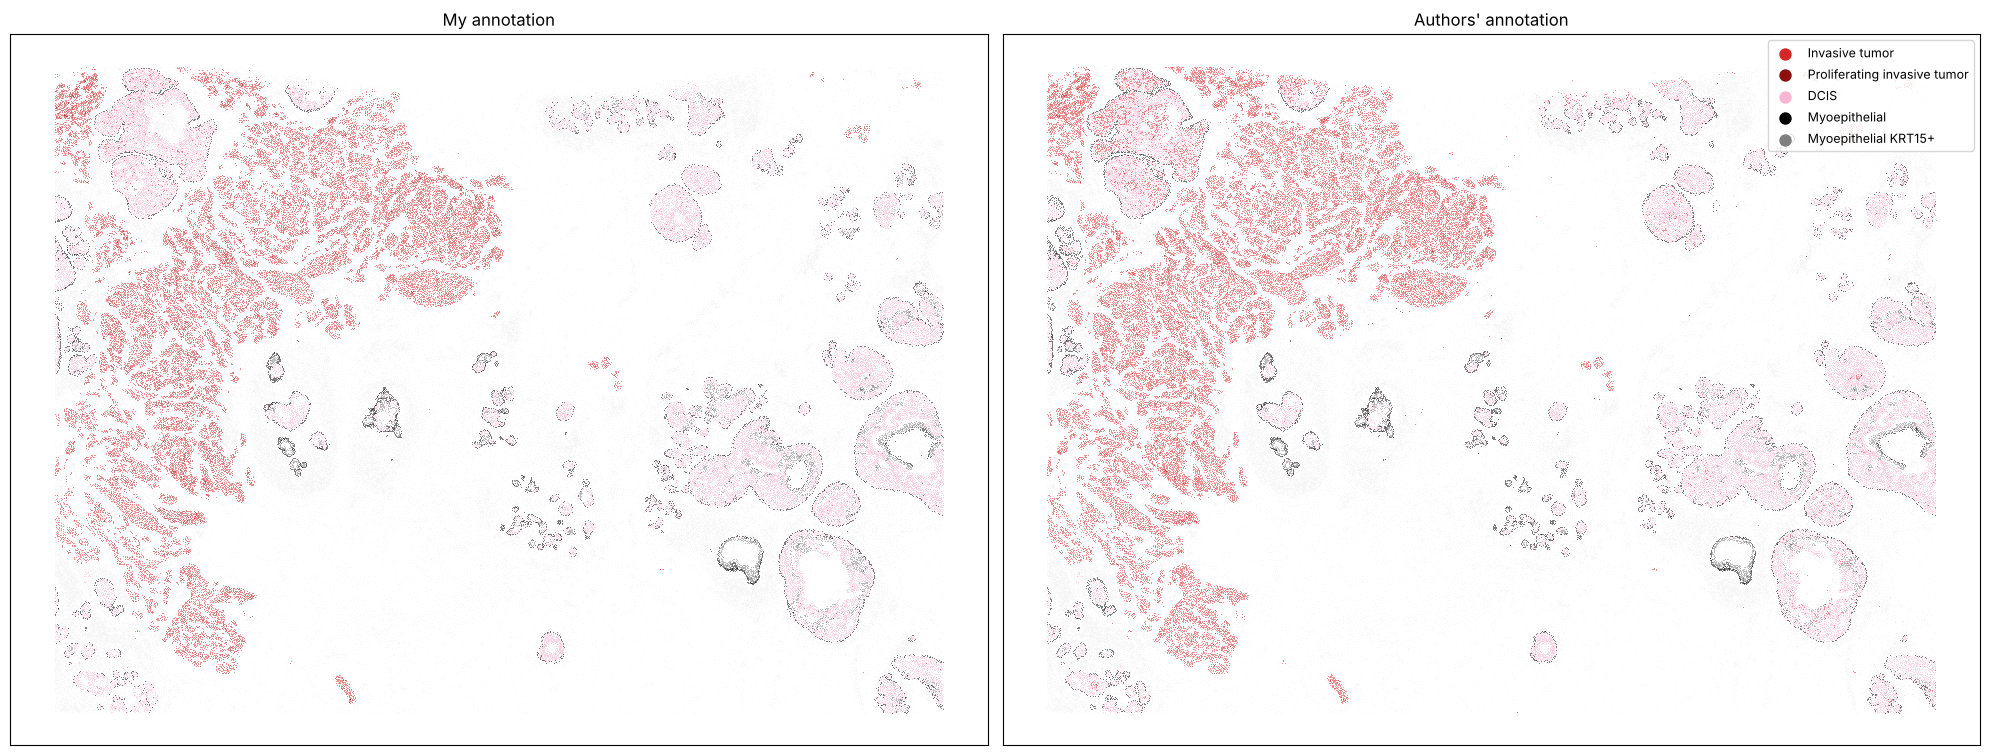

In [11]:
TUMOR_COLORS = {"Invasive tumor": "#d62728", "Proliferating invasive tumor": "#8c1010", "DCIS": "#f7b6d2",
                "Myoepithelial": "#000000", "Myoepithelial KRT15+": "#7f7f7f"}
xy = xe.obsm["spatial"]
fig, axes = plt.subplots(1, 2, figsize=(20, 7.5))
for ax, lab, name in [(axes[0], mine_xe, "My annotation"), (axes[1], auth_xe, "Authors' annotation")]:
    rest = ~np.isin(lab, list(TUMOR_COLORS))
    ax.scatter(xy[rest, 0], xy[rest, 1], s=0.1, c="#eeeeee", rasterized=True, linewidths=0)
    for c, col in TUMOR_COLORS.items():
        m = lab == c
        ax.scatter(xy[m, 0], xy[m, 1], s=0.2, c=col, rasterized=True, linewidths=0, label=c)
    ax.set_aspect("equal"); ax.invert_yaxis(); ax.set(title=name, xticks=[], yticks=[])
axes[1].legend(markerscale=20, loc="upper right", fontsize=9)
plt.tight_layout(); plt.savefig(FIG_DIR / "xenium_tumor_compartments_vs_authors.png", dpi=120); plt.show()

In [12]:
# DCIS vs. invasive, on cells both call tumor epithelium
tum = {"Invasive tumor": "invasive", "Proliferating invasive tumor": "invasive", "DCIS": "DCIS"}
m_t, a_t = pd.Series(mine_xe).map(tum), pd.Series(auth_xe).map(tum)
both = m_t.notna() & a_t.notna()
ct = pd.crosstab(m_t[both].rename("mine"), a_t[both].rename("authors"))
print(f"tumor cells both annotations call DCIS or invasive: {both.sum():,}; "
      f"same compartment: {(m_t[both] == a_t[both]).mean():.1%}")
ct

tumor cells both annotations call DCIS or invasive: 55,505; same compartment: 96.4%


authors,DCIS,invasive
mine,,
DCIS,21790,1900
invasive,104,31711


In [13]:
# my two DCIS groups vs. theirs: the numbering is arbitrary, the split may still match
dcis = xe.obs["cell_type"].isin(["DCIS 1", "DCIS 2"]) & xe.obs["authors"].isin(["DCIS_1", "DCIS_2"])
pd.crosstab(xe.obs.loc[dcis, "cell_type"].astype(str), xe.obs.loc[dcis, "authors"], normalize="index").round(2)

authors,DCIS_1,DCIS_2
cell_type,,
DCIS 1,0.02,0.98
DCIS 2,0.93,0.07


**Immune populations.** The paper reports T cells, B cells, two macrophage groups, two rare DC subsets (LAMP3+ and IRF7+) and mast cells. Does my annotation recover each?

In [14]:
immune = ["CD4+ T", "CD8+ T / NK", "B / plasma", "Macrophages", "Mature DCs", "pDCs", "Mast cells"]
tab_xe.reindex(immune)

,my cells,their cells,% of mine they agree with,% of theirs I recover
type,,,,
CD4+ T,16221,8431,47.8,92.0
CD8+ T / NK,9055,6931,54.1,70.7
B / plasma,8564,4980,57.6,99.0
Macrophages,16888,12672,62.2,82.9
Mature DCs,640,298,46.2,99.3
pDCs,612,492,75.8,94.3
Mast cells,722,166,23.0,100.0


### A5 · KDE link

Notebook 03 flags cells whose own type explains them poorly ("outlier") or another type explains them much better ("fits another type"). This section tests whether those flags are **associated with** disagreement with the publication labels.

A higher disagreement rate among flagged cells is useful evidence, but not independent proof of misannotation: the publication labels are a reference, not infallible ground truth. This comparison also excludes cells that are missing, unmapped, or explicitly unassigned on either side; the eligible-cell count is reported by the helper outputs.


**What this test can show.** An association between KDE flags and reference disagreement. It does not measure the sensitivity, specificity or positive predictive value of the KDE for truly wrong labels, because no ground truth exists; the reference itself differs in granularity and marker panel. The comparison is conditional on both annotations assigning a label. In notebook 04 the CODEX KDE flags come from the revised (post hoc) labels.

In [15]:
kde_xe = pd.read_csv(RESULTS_DIR / "xenium_kde.csv", dtype={"cell_id": str}).set_index("cell_id")
missing_ids = kde_xe.index.difference(xe.obs_names)
if len(missing_ids):
    raise ValueError(f"{len(missing_ids):,} KDE cell IDs are absent from xe.obs_names; regenerate notebook 03 outputs or check IDs.")
kde_xe = kde_xe.loc[xe.obs_names.intersection(kde_xe.index)]
k_mine = xe.obs.loc[kde_xe.index, "mine_common"].to_numpy()
k_auth = xe.obs.loc[kde_xe.index, "auth_common"].to_numpy()
k_comp = kde_xe["best_other"].map(XE_MINE).to_numpy()

rate_xe, or_xe, p_xe, comp_xe, n_xe = kde_link(kde_xe, k_mine, k_auth, k_comp)
print(f"odds ratio (flagged vs. confirmed, disagreeing with authors): {or_xe:.2f}  (Fisher p = {p_xe:.1e})")
print(f"fits another type AND disagreeing: {n_xe:,} cells; KDE competitor = authors' label in {comp_xe:.1f}%")
rate_xe

odds ratio (flagged vs. confirmed, disagreeing with authors): 2.27  (Fisher p = 1.1e-259)
fits another type AND disagreeing: 3,215 cells; KDE competitor = authors' label in 59.9%


,cells,% disagree with authors
flag,,
confirmed,146170,23.8
outlier,624,37.3
fits another type,7699,41.8


**Controlling for cell type.** The flag rate and the disagreement rate both vary strongly between types. The crude odds ratio above
can therefore reflect type composition alone. The Mantel–Haenszel odds ratio pools the 2×2 tables computed **within** each of my types.
The Fisher p-value above treats cells as independent replicates. They are not: neighboring cells are correlated, and Xenium is a single section.
So the p-value is reported for completeness, and the effect sizes are what to read.

In [16]:
ok = valid_assigned_mask(k_mine, k_auth)
mh_xe = mantel_haenszel_or(kde_xe["flag"].to_numpy()[ok] != "confirmed", (k_mine != k_auth)[ok],
                           xe.obs.loc[kde_xe.index, "cell_type"].astype(str).to_numpy()[ok])
print(f"Xenium odds ratio, crude: {or_xe:.2f}   stratified by my cell type (Mantel-Haenszel): {mh_xe:.2f}")

Xenium odds ratio, crude: 2.27   stratified by my cell type (Mantel-Haenszel): 2.91


In [17]:
# the same, per my type: disagreement among confirmed vs. flagged cells
d = pd.DataFrame({"type": xe.obs.loc[kde_xe.index, "cell_type"].astype(str).to_numpy(),
                  "flagged": kde_xe["flag"].to_numpy() != "confirmed",
                  "disagree": k_mine != k_auth, "ok": (k_auth != "unassigned")})
d = d[d.ok]
per_type_xe = d.groupby(["type", "flagged"])["disagree"].mean().unstack().mul(100).round(1)
per_type_xe.columns = ["% disagree | confirmed", "% disagree | flagged"]
per_type_xe["flagged cells"] = d.groupby("type")["flagged"].sum()
per_type_xe.sort_values("flagged cells", ascending=False)

,% disagree | confirmed,% disagree | flagged,flagged cells
type,,,
DCIS 1,20.3,41.5,1038
Invasive tumor,0.3,5.7,922
CAF / myofibroblasts,9.9,33.2,776
Proliferating invasive tumor,51.0,79.3,757
DCIS 2,2.6,11.7,724
Fibroblasts,0.0,0.8,606
Macrophages CD163+,37.7,35.6,478
Macrophages APOC1+,36.9,51.0,431
CD4+ T cells,51.7,73.2,380


## Part B · CODEX colorectal cancer

### B1 · Name mapping

- **Merged on both sides:** the authors split macrophages into six classes and CD4+ T cells into three. These merge into one macrophage class and one CD4+ T class.
- **No counterpart:** my "Follicular DCs" and "CD138+ cells" have no author class. Their NK and generic CD3+ T cells have none of mine.
  These categories keep their own name, so cells in them can only disagree.
- **Granzyme B+ cells:** my cluster was CD68+ GzmB+, so it maps to macrophages. The authors also have a "CD68+ macrophages GzmB+" class.
- **Unassigned:** the authors' "dirt", "undefined" and the three mixed classes ("immune cells", "immune cells / vasculature", "tumor cells / immune cells"), and my `unknown`.

In [18]:
CX_MINE = {
    "Tumor cells": "Tumor", "Tumor cells MUC-1+": "Tumor", "Smooth muscle": "Smooth muscle", "Stroma": "Stroma",
    "Vasculature": "Vasculature", "Lymphatics": "Lymphatics", "Nerves": "Nerves",
    "CD4+ T cells": "CD4+ T", "Tregs": "Tregs", "CD8+ T cells": "CD8+ T", "B cells": "B cells",
    "Follicular DCs": "Follicular DCs", "Plasma cells": "Plasma cells", "CD138+ cells": "CD138+ cells",
    "Macrophages CD68+CD163+": "Macrophages", "Granzyme B+ cells": "Macrophages",
    "CD11c+ myeloid cells": "CD11c+ myeloid", "Granulocytes": "Granulocytes", "unknown": "unassigned",
}
CX_AUTH = {
    "tumor cells": "Tumor", "smooth muscle": "Smooth muscle", "stroma": "Stroma", "adipocytes": "Stroma",
    "vasculature": "Vasculature", "lymphatics": "Lymphatics", "nerves": "Nerves",
    "CD4+ T cells CD45RO+": "CD4+ T", "CD4+ T cells": "CD4+ T", "CD4+ T cells GATA3+": "CD4+ T",
    "Tregs": "Tregs", "CD8+ T cells": "CD8+ T", "NK cells": "NK / other T", "CD3+ T cells": "NK / other T",
    "B cells": "B cells", "plasma cells": "Plasma cells",
    "CD68+CD163+ macrophages": "Macrophages", "CD68+ macrophages": "Macrophages", "CD163+ macrophages": "Macrophages",
    "CD11b+CD68+ macrophages": "Macrophages", "CD68+ macrophages GzmB+": "Macrophages", "CD11b+ monocytes": "Macrophages",
    "CD11c+ DCs": "CD11c+ myeloid", "granulocytes": "Granulocytes",
    "dirt": "unassigned", "undefined": "unassigned", "immune cells": "unassigned",
    "immune cells / vasculature": "unassigned", "tumor cells / immune cells": "unassigned",
}
CX_ORDER = ["Tumor", "Smooth muscle", "Stroma", "Vasculature", "Lymphatics", "Nerves", "CD4+ T", "Tregs", "CD8+ T",
            "NK / other T", "B cells", "Follicular DCs", "Plasma cells", "CD138+ cells", "Macrophages",
            "CD11c+ myeloid", "Granulocytes", "unassigned"]

pd.DataFrame({"common type": CX_ORDER,
              "my types": [", ".join(k for k, v in CX_MINE.items() if v == c) for c in CX_ORDER],
              "authors' types": [", ".join(k for k, v in CX_AUTH.items() if v == c) for c in CX_ORDER]}).set_index("common type")

,my types,authors' types
common type,,
Tumor,"Tumor cells, Tumor cells MUC-1+",tumor cells
Smooth muscle,Smooth muscle,smooth muscle
Stroma,Stroma,"stroma, adipocytes"
Vasculature,Vasculature,vasculature
Lymphatics,Lymphatics,lymphatics
Nerves,Nerves,nerves
CD4+ T,CD4+ T cells,"CD4+ T cells CD45RO+, CD4+ T cells, CD4+ T cel..."
Tregs,Tregs,Tregs
CD8+ T,CD8+ T cells,CD8+ T cells


In [19]:
cx = sc.read_h5ad(RESULTS_DIR / "codex_annotated.h5ad")
raw = pd.read_csv(CX_FILE, usecols=["CellID", "ClusterName", "neighborhood name"])
raw["CellID"] = raw["CellID"].astype(str)
if raw["CellID"].duplicated().any():
    raise ValueError("CODEX source CSV contains duplicate CellID values.")
raw = raw.set_index("CellID")
if not cx.obs_names.is_unique:
    raise ValueError("CODEX AnnData obs_names are not unique.")
if not set(raw["ClusterName"].dropna().unique()).issubset(CX_AUTH):
    raise ValueError(f"Unmapped CODEX author labels: {sorted(set(raw['ClusterName'].dropna().unique()) - set(CX_AUTH))}")
assert set(CX_AUTH) == set(raw["ClusterName"].unique()), "unmapped author label"

cx.obs["authors"] = raw["ClusterName"].reindex(cx.obs_names).values
cx.obs["auth_neighborhood"] = raw["neighborhood name"].reindex(cx.obs_names).values
cx.obs["mine_common"] = cx.obs["cell_type"].astype(str).map(CX_MINE)
cx.obs["auth_common"] = cx.obs["authors"].map(CX_AUTH)
if cx.obs["mine_common"].isna().any():
    missing = sorted(cx.obs.loc[cx.obs["mine_common"].isna(), "cell_type"].astype(str).unique())
    raise ValueError(f"Unmapped CODEX labels in CX_MINE: {missing}")
print(f"{cx.n_obs:,} cells; authors' label found for {cx.obs['authors'].notna().mean():.1%}")

254,639 cells; authors' label found for 100.0%



### B2 · Cell-level agreement

**Note on blinding.** The CODEX labels were revised in notebook 02 after a first version of this comparison had been seen.
Five clusters were relabeled `unknown` under a rule that uses only notebook-02 evidence (conflicting lineage markers or low signal).
The revision still makes the CODEX agreement below not fully blind. It also changes the comparison population: agreement is computed only on cells both
annotations assign, so moving ambiguous cells to `unknown` removes them from the denominator. Read agreement together with the coverage line.


In [20]:
mine_cx, auth_cx = cx.obs["mine_common"].to_numpy(dtype=object), cx.obs["auth_common"].to_numpy(dtype=object)
valid_cx = valid_assigned_mask(mine_cx, auth_cx)
if valid_cx.sum() == 0:
    raise ValueError("No CODEX cells have mapped, assigned labels on both sides.")
ari_common = adjusted_rand_score(auth_cx[valid_cx], mine_cx[valid_cx])
fine_valid_cx = cx.obs["authors"].notna().to_numpy() & cx.obs["cell_type"].notna().to_numpy()
ari_fine = adjusted_rand_score(cx.obs.loc[fine_valid_cx, "authors"].astype(str),
                               cx.obs.loc[fine_valid_cx, "cell_type"].astype(str))
tab_cx, acc_cx = agreement_tables(mine_cx, auth_cx)
print(f"Cells with mapped, assigned labels on both sides: {valid_cx.sum():,}/{cx.n_obs:,} ({valid_cx.mean():.1%})")
print(f"ARI (common vocabulary, assigned cells): {ari_common:.3f}   ARI (original labels, non-missing cells): {ari_fine:.3f}")
print(f"agreement on cells both annotations assign: {acc_cx:.1f}%")
allc = ~pd.isna(mine_cx) & ~pd.isna(auth_cx)
print(f"with 'unassigned' kept as a category (all {allc.sum():,} cells): ARI {adjusted_rand_score(auth_cx[allc], mine_cx[allc]):.3f}, "
      f"same label {100 * (mine_cx[allc] == auth_cx[allc]).mean():.1f}%  |  excluded from the main metrics: {(~valid_cx).sum():,} cells")
tab_cx.reindex([c for c in CX_ORDER if c in tab_cx.index])

Cells with mapped, assigned labels on both sides: 163,091/254,639 (64.0%)
ARI (common vocabulary, assigned cells): 0.372   ARI (original labels, non-missing cells): 0.145
agreement on cells both annotations assign: 59.3%


with 'unassigned' kept as a category (all 254,639 cells): ARI 0.172, same label 43.2%  |  excluded from the main metrics: 91,548 cells


,my cells,their cells,% of mine they agree with,% of theirs I recover
type,,,,
Tumor,19630,23102,89.3,75.9
Smooth muscle,9453,21848,84.5,36.6
Stroma,21981,14068,26.0,40.6
Vasculature,16948,10886,59.0,91.8
Lymphatics,831,312,23.2,61.9
Nerves,1092,47,0.0,0.0
CD4+ T,16590,16055,48.3,50.0
Tregs,9690,2583,17.3,65.1
CD8+ T,17271,15215,74.5,84.6


**Primary (blind) vs. post hoc labels.** The first version of notebook 02 named the five revised clusters; those names were fixed before any
comparison with the authors and are therefore the **primary, blind** annotation. The revised labels (five clusters set to `unknown`) are a
**post hoc** analysis. Both are reported, so the effect of the revision is visible on its own.

In [21]:
V1_NAMES = {"10": "Follicular DCs", "6": "Plasma cells", "19": "CD138+ cells", "23": "Granzyme B+ cells", "0": "Tumor cells"}
cl_cx = cx.obs["cluster"].astype(str)
assert all((cx.obs.loc[cl_cx == k, "cell_type"] == "unknown").all() for k in V1_NAMES), "cluster numbering changed"
v1 = cx.obs["cell_type"].astype(str).where(~cl_cx.isin(list(V1_NAMES)), cl_cx.map(V1_NAMES))
mine_v1 = v1.map(CX_MINE).to_numpy(dtype=object)

def metrics(mine, auth):
    ok = valid_assigned_mask(mine, auth)
    allc = ~pd.isna(mine) & ~pd.isna(auth)
    return {"coverage %": round(100 * ok.mean(), 1),
            "ARI (assigned cells)": round(adjusted_rand_score(auth[ok], mine[ok]), 3),
            "same label, assigned cells %": round(100 * (mine[ok] == auth[ok]).mean(), 1),
            "ARI (unassigned kept)": round(adjusted_rand_score(auth[allc], mine[allc]), 3),
            "same label, all cells %": round(100 * (mine[allc] == auth[allc]).mean(), 1)}

pd.DataFrame({"primary: first-version labels (blind)": metrics(mine_v1, auth_cx),
              "post hoc: revised labels": metrics(mine_cx, auth_cx)}).T

,coverage %,ARI (assigned cells),"same label, assigned cells %",ARI (unassigned kept),"same label, all cells %"
primary: first-version labels (blind),78.4,0.371,57.3,0.246,47.4
post hoc: revised labels,64.0,0.372,59.3,0.172,43.2


**Result.** The revision did **not** make the annotation agree better with the authors. It mainly removed cells from the comparison.
- **Coverage:** it fell from 78% to 64% of cells.
- **Agreement on assigned cells:** almost unchanged (ARI 0.371 → 0.372; same label 57.3% → 59.3%).
- **With `unassigned` kept as a category:** agreement falls (ARI 0.246 → 0.172).

The first-version row is the primary, blind result.

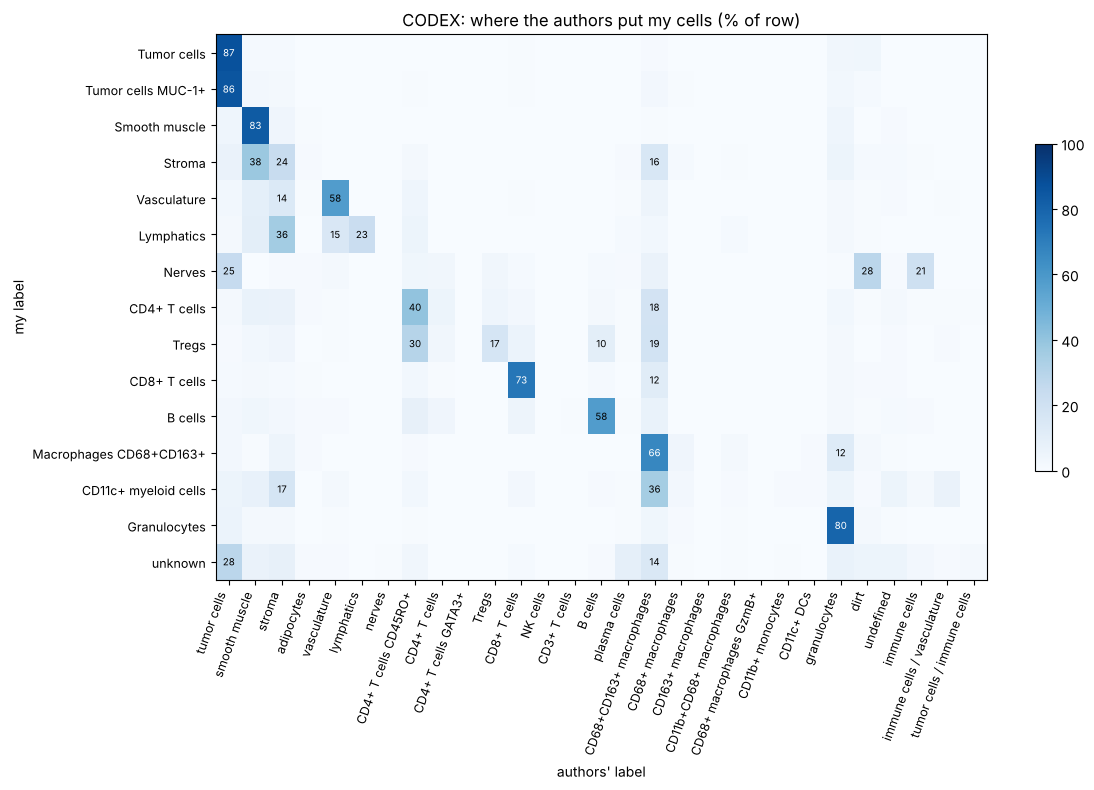

In [22]:
fig, ax = plt.subplots(figsize=(12, 8))
im = plot_confusion(cx.obs["cell_type"].astype(str).to_numpy(), cx.obs["authors"].to_numpy(),
                    list(CX_MINE), list(CX_AUTH), "CODEX: where the authors put my cells (% of row)", ax)
plt.colorbar(im, ax=ax, shrink=0.6)
plt.tight_layout(); plt.savefig(FIG_DIR / "codex_confusion.png", dpi=120); plt.show()

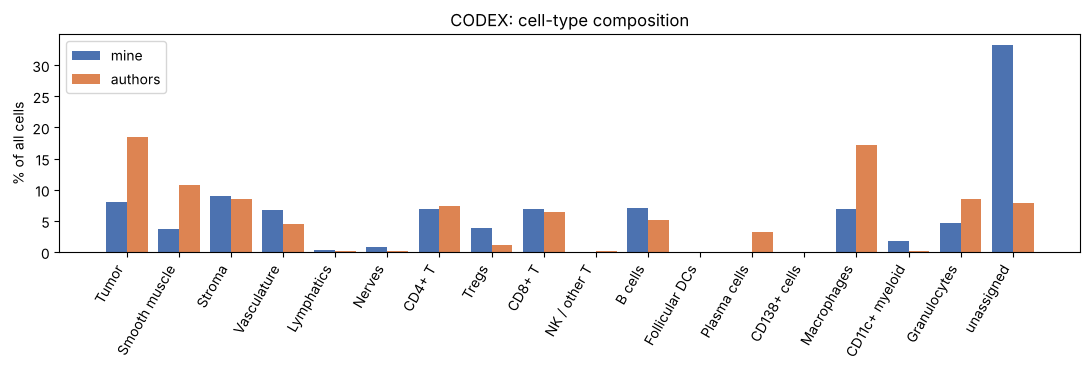

In [23]:
fig, ax = plt.subplots(figsize=(11, 3.8))
plot_composition(mine_cx, auth_cx, CX_ORDER, "CODEX: cell-type composition", ax)
plt.tight_layout(); plt.show()


**The clusters questioned in notebooks 02 and 03.** Five of them are now `unknown`, and two keep a provisional name.
What do the authors call those cells? They are identified by cluster number (resolution selected in notebook 02).


In [24]:
def top3(mask):
    vc = cx.obs.loc[mask, "authors"].value_counts(normalize=True).head(3) * 100
    return ", ".join(f"{k} {v:.0f}%" for k, v in vc.items())

cl = cx.obs["cluster"].astype(str)
questioned = {
    "cluster 10: CD21-high (was 'Follicular DCs')": cl == "10",
    "cluster 6: CD38-high (was 'Plasma cells')": cl == "6",
    "cluster 19: CD138-high (was 'CD138+ cells')": cl == "19",
    "cluster 23: Granzyme B-high (was 'Granzyme B+ cells')": cl == "23",
    "cluster 0: dim CDX2+ (was 'Tumor cells')": cl == "0",
    "Nerves (provisional)": cx.obs["cell_type"] == "Nerves",
    "Tregs": cx.obs["cell_type"] == "Tregs",
    "all unknown": cx.obs["cell_type"] == "unknown",
}
# the five relabeled clusters must be unknown in the current annotation (cluster numbering check)
for name, m in list(questioned.items())[:5]:
    assert m.any() and (cx.obs.loc[m, "cell_type"] == "unknown").all(), f"{name}: numbering changed, update this table"
pd.DataFrame({"cells": {k: int(m.sum()) for k, m in questioned.items()},
              "current label": {k: ", ".join(cx.obs.loc[m, "cell_type"].astype(str).unique()) for k, m in questioned.items()},
              "authors' top 3 labels": {k: top3(m) for k, m in questioned.items()}})

,cells,current label,authors' top 3 labels
cluster 10: CD21-high (was 'Follicular DCs'),6367,unknown,"CD68+CD163+ macrophages 49%, granulocytes 12%,..."
cluster 6: CD38-high (was 'Plasma cells'),16627,unknown,"plasma cells 42%, CD68+CD163+ macrophages 13%,..."
cluster 19: CD138-high (was 'CD138+ cells'),2750,unknown,"tumor cells 63%, tumor cells / immune cells 14..."
cluster 23: Granzyme B-high (was 'Granzyme B+ cells'),758,unknown,"CD68+CD163+ macrophages 36%, CD68+ macrophages..."
cluster 0: dim CDX2+ (was 'Tumor cells'),16947,unknown,"tumor cells 61%, dirt 8%, granulocytes 8%"
Nerves (provisional),2197,Nerves,"dirt 28%, tumor cells 25%, immune cells 21%"
Tregs,9956,Tregs,"CD4+ T cells CD45RO+ 30%, CD68+CD163+ macropha..."
all unknown,84691,unknown,"tumor cells 28%, CD68+CD163+ macrophages 14%, ..."


### B3 · QC check

The authors label 7,357 cells "dirt" (debris). Are the cells my QC removed enriched for dirt, and where do the remaining dirt cells end up in my annotation?

In [25]:
removed = raw.index.difference(cx.obs_names)
dirt_all = (raw["ClusterName"] == "dirt").mean() * 100
dirt_removed = (raw.loc[removed, "ClusterName"] == "dirt").mean() * 100
kept_dirt = cx.obs["authors"] == "dirt"
print(f"{len(removed):,} cells removed by my QC: {dirt_removed:.1f}% are 'dirt' (vs. {dirt_all:.1f}% of all cells)")
print(f"'dirt' cells removed by my QC: {(raw.loc[removed, 'ClusterName'] == 'dirt').sum():,} of {(raw['ClusterName'] == 'dirt').sum():,}")
(cx.obs.loc[kept_dirt, "cell_type"].value_counts(normalize=True).head(6) * 100).round(1).rename("% of remaining 'dirt' cells")

3,746 cells removed by my QC: 7.3% are 'dirt' (vs. 2.8% of all cells)
'dirt' cells removed by my QC: 275 of 7,357


cell_type
unknown                    64.3
Nerves                      8.8
Macrophages CD68+CD163+     5.2
Tumor cells                 4.9
Stroma                      4.4
Granulocytes                2.7
Name: % of remaining 'dirt' cells, dtype: float64

### B4 · Main findings of the paper

**1. Immune composition differs between CLR and DII patients.** For each patient, I take the fraction of each type among all cells,
then compare the two groups (Mann–Whitney U test, 17 CLR vs. 18 DII patients). This is done twice, once with my labels and once with the authors'.
The question is whether both labelings give the same direction and similar significance.

**Statistical note:** the cell-level annotations are not independent replicates. Group comparisons use patient-level cell fractions. P-values are two-sided Mann–Whitney U tests; Benjamini–Hochberg adjusted q-values are reported across the tested cell types separately for each annotation. Treat these comparisons as exploratory, especially with small patient counts.


In [26]:
patient = cx.obs["patient"].astype(str)
group = cx.obs.groupby("patient", observed=True)["group"].first()
group.index = group.index.astype(str)

def group_test(labels, types):
    frac = pd.crosstab(patient, labels, normalize="index").reindex(columns=types, fill_value=0) * 100
    g = group.reindex(frac.index)
    rows = []
    if not {"CLR", "DII"}.issubset(set(g.dropna())):
        raise ValueError("Expected both CLR and DII groups in patient metadata.")
    for t in types:
        a = frac.loc[g == "CLR", t].dropna()
        b = frac.loc[g == "DII", t].dropna()
        if len(a) < 2 or len(b) < 2:
            p = np.nan
        else:
            p = mannwhitneyu(a, b, alternative="two-sided").pvalue
        rows.append({"type": t, "CLR median %": a.median(), "DII median %": b.median(), "p": p,
                     "n_CLR": len(a), "n_DII": len(b)})
    result = pd.DataFrame(rows).set_index("type")
    result["q_BH"] = bh_adjust(result["p"].to_numpy())
    return result

immune_cx = ["CD4+ T", "Tregs", "CD8+ T", "B cells", "Plasma cells", "Macrophages", "CD11c+ myeloid", "Granulocytes"]
# test only types that exist in both labelings (a type with 0 cells on one side cannot be compared)
present = lambda lab: set(pd.Series(lab).dropna().unique())
dropped = [t for t in immune_cx if t not in present(mine_cx) or t not in present(auth_cx)]
if dropped:
    print(f"not tested (absent from one labeling): {dropped}")
immune_cx = [t for t in immune_cx if t not in dropped]
gm, ga = group_test(mine_cx, immune_cx), group_test(auth_cx, immune_cx)
comp = pd.concat({"mine": gm, "authors": ga}, axis=1)
comp[("", "same direction")] = np.sign(gm["CLR median %"] - gm["DII median %"]) == np.sign(ga["CLR median %"] - ga["DII median %"])
comp.round(3)

not tested (absent from one labeling): ['Plasma cells']


mine                                         \
               CLR median % DII median %      p n_CLR n_DII   q_BH   
type                                                                 
CD4+ T                5.561        5.848  0.882    17    18  0.882   
Tregs                 2.575        3.665  0.077    17    18  0.181   
CD8+ T                5.510        7.015  0.125    17    18  0.218   
B cells               9.434        1.249  0.001    17    18  0.007   
Macrophages           5.612        7.371  0.754    17    18  0.880   
CD11c+ myeloid        1.175        1.453  0.609    17    18  0.853   
Granulocytes          2.075        4.105  0.058    17    18  0.181   

                    authors                                         \
               CLR median % DII median %      p n_CLR n_DII   q_BH   
type                                                                 
CD4+ T                7.038        5.819  0.419    17    18  0.489   
Tregs                 0.867        1.022  0.058    17    18  0.109   
CD8+ T                6.365        6.087  0.632    17    18  0.632   
B cells               5.000        1.244  0.001    17    18  0.005   
Macrophages          12.699       19.349  0.024    17    18  0.083   
CD11c+ myeloid        0.101        0.052  0.112    17    18  0.157   
Granulocytes          4.203        8.033  0.062    17    18  0.109   

                               
               same direction  
type                           
CD4+ T                  False  
Tregs                    True  
CD8+ T                  False  
B cells                  True  
Macrophages              True  
CD11c+ myeloid          False  
Granulocytes             True

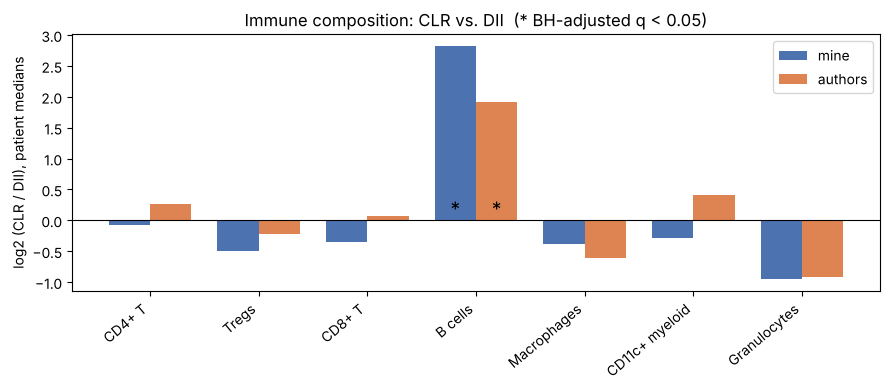

In [27]:
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(immune_cx)); w = 0.38
lfc = lambda g: np.log2((g["CLR median %"] + 0.1) / (g["DII median %"] + 0.1))
ax.bar(x - w / 2, lfc(gm), w, color="#4c72b0", label="mine")
ax.bar(x + w / 2, lfc(ga), w, color="#dd8452", label="authors")
for xi, (pm, pa) in enumerate(zip(gm["q_BH"], ga["q_BH"])):
    for dx, p in [(-w / 2, pm), (w / 2, pa)]:
        if p < 0.05:
            ax.text(xi + dx, 0, "*", ha="center", va="bottom", fontsize=14)
ax.axhline(0, color="k", lw=0.8)
ax.set_xticks(x, immune_cx, rotation=40, ha="right")
ax.set(ylabel="log2 (CLR / DII), patient medians", title="Immune composition: CLR vs. DII  (* BH-adjusted q < 0.05)")
ax.legend(); plt.tight_layout(); plt.savefig(FIG_DIR / "codex_clr_vs_dii.png", dpi=120); plt.show()

**2. Lymphoid aggregates (follicles) in CLR patients.** The authors found a "Follicle" cellular neighborhood that is characteristic of CLR.
My counterpart, built only from my labels and the spatial graph of notebook 02, is a B cell **in an aggregate**: one with
at least `AGG_MIN` of its neighbors (within 30 µm) also B cells.

- Per patient, the fraction of all cells that are aggregate B cells (mine) and the fraction of cells in the "Follicle" neighborhood (authors).
- The overlap: how many of my aggregate B cells lie in the authors' Follicle neighborhood.

**Interpretation limit:** the neighbor-fraction rule is not the same algorithm as the authors' cellular-neighborhood classification. Differences can reflect the definitions as well as annotation quality. Patients, not individual cells, are the independent units for the group comparison.


In [28]:
A = cx.obsp["spatial_connectivities"]
is_b = (cx.obs["cell_type"] == "B cells").to_numpy()
deg = np.asarray(A.sum(axis=1)).ravel()
b_frac = np.asarray(A @ is_b.astype(float)).ravel() / np.maximum(deg, 1)
cx.obs["b_aggregate"] = is_b & (deg > 0) & (b_frac >= AGG_MIN)
cx.obs["auth_follicle"] = cx.obs["auth_neighborhood"] == "Follicle"

per_pat = cx.obs.groupby(patient.values, observed=True)[["b_aggregate", "auth_follicle"]].mean() * 100
per_pat["group"] = group.reindex(per_pat.index).values
for col, name in [("b_aggregate", "my aggregate B cells"), ("auth_follicle", "authors' Follicle neighborhood")]:
    a, b = per_pat.loc[per_pat.group == "CLR", col], per_pat.loc[per_pat.group == "DII", col]
    print(f"{name:32s} CLR median {a.median():5.2f}%   DII median {b.median():5.2f}%   p = {mannwhitneyu(a, b).pvalue:.4f}")
ov = cx.obs.loc[cx.obs["b_aggregate"], "auth_follicle"].mean() * 100
print(f"\nmy aggregate B cells inside the authors' Follicle neighborhood: {ov:.1f}% "
      f"(all cells: {cx.obs['auth_follicle'].mean() * 100:.1f}%)")

my aggregate B cells             CLR median  4.19%   DII median  0.00%   p = 0.0004
authors' Follicle neighborhood   CLR median  3.79%   DII median  0.02%   p = 0.0003

my aggregate B cells inside the authors' Follicle neighborhood: 82.2% (all cells: 5.1%)


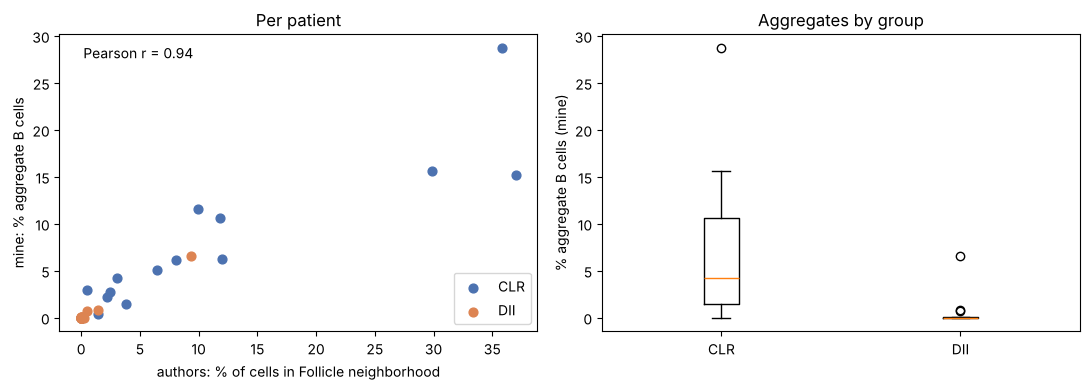

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for g, col in [("CLR", "#4c72b0"), ("DII", "#dd8452")]:
    s = per_pat[per_pat.group == g]
    axes[0].scatter(s["auth_follicle"], s["b_aggregate"], c=col, label=g, s=40)
axes[0].set(xlabel="authors: % of cells in Follicle neighborhood", ylabel="mine: % aggregate B cells",
            title="Per patient"); axes[0].legend()
r = np.corrcoef(per_pat["auth_follicle"], per_pat["b_aggregate"])[0, 1]
axes[0].text(0.05, 0.92, f"Pearson r = {r:.2f}", transform=axes[0].transAxes)
data = [per_pat.loc[per_pat.group == g, "b_aggregate"] for g in ["CLR", "DII"]]
axes[1].boxplot(data); axes[1].set_xticks([1, 2], ["CLR", "DII"])
axes[1].set(ylabel="% aggregate B cells (mine)", title="Aggregates by group")
plt.tight_layout(); plt.savefig(FIG_DIR / "codex_aggregates_vs_follicles.png", dpi=120); plt.show()

### B5 · KDE link

In [30]:
kde_cx = pd.read_csv(RESULTS_DIR / "codex_kde.csv", dtype={"cell_id": str}).set_index("cell_id")
missing_ids = kde_cx.index.difference(cx.obs_names)
if len(missing_ids):
    raise ValueError(f"{len(missing_ids):,} KDE cell IDs are absent from cx.obs_names; regenerate notebook 03 outputs or check IDs.")
kde_cx = kde_cx.loc[cx.obs_names.intersection(kde_cx.index)]
k_mine = cx.obs.loc[kde_cx.index, "mine_common"].to_numpy()
k_auth = cx.obs.loc[kde_cx.index, "auth_common"].to_numpy()
k_comp = kde_cx["best_other"].map(CX_MINE).to_numpy()

rate_cx, or_cx, p_cx, comp_cx, n_cx = kde_link(kde_cx, k_mine, k_auth, k_comp)
print(f"odds ratio (flagged vs. confirmed, disagreeing with authors): {or_cx:.2f}  (Fisher p = {p_cx:.1e})")
print(f"fits another type AND disagreeing: {n_cx:,} cells; KDE competitor = authors' label in {comp_cx:.1f}%")
rate_cx

odds ratio (flagged vs. confirmed, disagreeing with authors): 2.36  (Fisher p = 0.0e+00)
fits another type AND disagreeing: 7,042 cells; KDE competitor = authors' label in 28.3%


,cells,% disagree with authors
flag,,
confirmed,149969,39.0
outlier,1965,43.2
fits another type,11157,63.1


**Controlling for cell type and for patients.** As for Xenium, the Mantel–Haenszel odds ratio removes confounding by type composition.
Here the patient is the biological unit. For each patient, the disagreement rate of flagged cells is compared with that of confirmed cells,
and the per-patient differences are tested with a Wilcoxon signed-rank test across the 35 patients.

In [31]:
ok = valid_assigned_mask(k_mine, k_auth)
flag_ok = kde_cx["flag"].to_numpy()[ok] != "confirmed"
dis_ok = (k_mine != k_auth)[ok]
mh_cx = mantel_haenszel_or(flag_ok, dis_ok, cx.obs.loc[kde_cx.index, "cell_type"].astype(str).to_numpy()[ok])
print(f"CODEX odds ratio, crude: {or_cx:.2f}   stratified by my cell type (Mantel-Haenszel): {mh_cx:.2f}")

pat_rates, pat_diff, pat_p, pat_dropped = patient_level_link(flag_ok, dis_ok, cx.obs.loc[kde_cx.index, "patient"].astype(str).to_numpy()[ok])
print(f"patients where flagged cells disagree more than confirmed cells: {(pat_diff > 0).sum()} of {len(pat_diff)}; "
      f"median difference {pat_diff.median():.1f} percentage points; Wilcoxon p = {pat_p:.1e}; "
      f"patients left out (< 20 eligible cells in a group): {pat_dropped}")

CODEX odds ratio, crude: 2.36   stratified by my cell type (Mantel-Haenszel): 2.84


patients where flagged cells disagree more than confirmed cells: 35 of 35; median difference 21.6 percentage points; Wilcoxon p = 5.8e-11; patients left out (< 20 eligible cells in a group): 0


In [32]:
d = pd.DataFrame({"type": cx.obs.loc[kde_cx.index, "cell_type"].astype(str).to_numpy(),
                  "flagged": kde_cx["flag"].to_numpy() != "confirmed",
                  "disagree": k_mine != k_auth, "ok": (k_auth != "unassigned")})
d = d[d.ok]
per_type_cx = d.groupby(["type", "flagged"])["disagree"].mean().unstack().mul(100).round(1)
per_type_cx.columns = ["% disagree | confirmed", "% disagree | flagged"]
per_type_cx["flagged cells"] = d.groupby("type")["flagged"].sum()
per_type_cx.sort_values("flagged cells", ascending=False)

,% disagree | confirmed,% disagree | flagged,flagged cells
type,,,
Tumor cells MUC-1+,7.6,38.3,1612
CD8+ T cells,23.4,49.1,1417
Stroma,73.5,82.2,1289
Tregs,81.2,92.4,1263
CD4+ T cells,50.8,66.0,951
Smooth muscle,14.7,23.2,922
Vasculature,39.8,63.5,869
Macrophages CD68+CD163+,24.1,35.1,866
Granulocytes,16.7,38.8,824


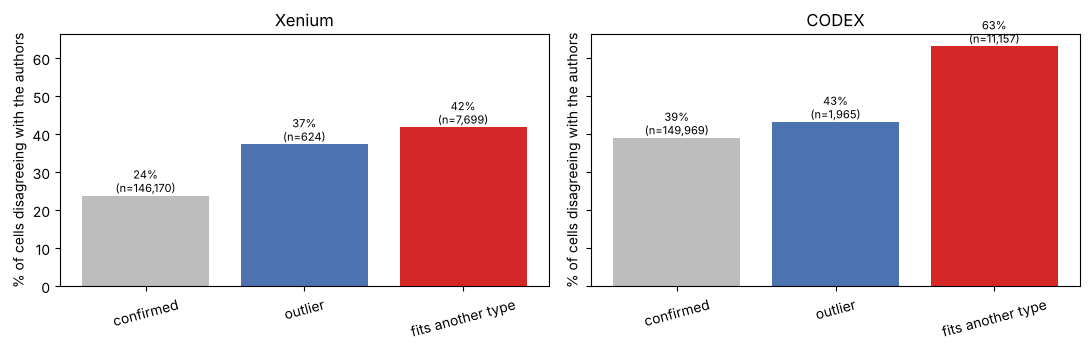

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, (name, r) in zip(axes, [("Xenium", rate_xe), ("CODEX", rate_cx)]):
    ax.bar(r.index, r["% disagree with authors"], color=["#bdbdbd", "#4c72b0", "#d62728"])
    for i, (v, n) in enumerate(zip(r["% disagree with authors"], r["cells"])):
        ax.text(i, v + 1, f"{v:.0f}%\n(n={n:,})", ha="center", fontsize=8)
    ax.set(title=name, ylabel="% of cells disagreeing with the authors"); ax.tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.savefig(FIG_DIR / "kde_flags_vs_disagreement.png", dpi=120); plt.show()

In [34]:
# Summary of this run (computed, not copied)
print("XENIUM")
print(f"  coverage {valid_xe.mean():.1%} of cells; ARI {adjusted_rand_score(auth_xe[valid_xe], mine_xe[valid_xe]):.3f}; agreement {acc_xe:.1f}%")
print(f"  KDE link: disagreement confirmed {rate_xe.loc['confirmed', '% disagree with authors']:.0f}% vs. "
      f"fits another type {rate_xe.loc['fits another type', '% disagree with authors']:.0f}%; "
      f"OR crude {or_xe:.2f}, stratified {mh_xe:.2f}; competitor = authors' label {comp_xe:.0f}%")
print("CODEX")
print(f"  coverage {valid_cx.mean():.1%} of cells; ARI {adjusted_rand_score(auth_cx[valid_cx], mine_cx[valid_cx]):.3f}; agreement {acc_cx:.1f}%")
sig = [t for t in immune_cx if gm.loc[t, "q_BH"] < 0.05 or ga.loc[t, "q_BH"] < 0.05]
print(f"  CLR vs. DII, q < 0.05 with either labeling: " + ", ".join(
      f"{t} (mine q={gm.loc[t, 'q_BH']:.3f}, authors q={ga.loc[t, 'q_BH']:.3f})" for t in sig))
print(f"  KDE link: disagreement confirmed {rate_cx.loc['confirmed', '% disagree with authors']:.0f}% vs. "
      f"fits another type {rate_cx.loc['fits another type', '% disagree with authors']:.0f}%; "
      f"OR crude {or_cx:.2f}, stratified {mh_cx:.2f}; patients with the effect {(pat_diff > 0).sum()}/{len(pat_diff)}")
print(f"  CODEX patients left out of the patient-level test: {pat_dropped}")


XENIUM


  coverage 94.2% of cells; ARI 0.550; agreement 75.3%
  KDE link: disagreement confirmed 24% vs. fits another type 42%; OR crude 2.27, stratified 2.91; competitor = authors' label 60%
CODEX


  coverage 64.0% of cells; ARI 0.372; agreement 59.3%
  CLR vs. DII, q < 0.05 with either labeling: B cells (mine q=0.007, authors q=0.005)
  KDE link: disagreement confirmed 39% vs. fits another type 63%; OR crude 2.36, stratified 2.84; patients with the effect 35/35
  CODEX patients left out of the patient-level test: 0


## Conclusion

The summary above is computed from this run. Interpret it with the following in mind:

- **Agreement metrics:** report ARI alongside the number and fraction of cells with valid mapped labels on both sides. ARI and agreement are not interchangeable; broad name mapping can increase agreement.
- **QC:** compare the author labels among removed cells with the full source dataset, and report both enrichment and the absolute number of removed cells.
- **Biological findings:** compare cell-type proportions at the patient level. The Mann–Whitney tests are exploratory, and the BH-adjusted q-values should be used for the plotted significance markers.
- **Spatial aggregates:** a B-cell neighborhood rule is an operational definition, not a direct reproduction of the authors' neighborhood algorithm. Correlation with the authors' Follicle label supports similarity, not equivalence.
- **KDE verification:** higher disagreement among flagged cells is evidence of association with annotation disagreement, not proof that a cell is mislabeled. Use the type-stratified odds ratio (and, for CODEX, the patient-level test) rather than the crude cell-level odds ratio and its Fisher p-value, which treats correlated cells as independent. The authors' labels are a useful reference, but not an infallible ground truth.

Before interpreting results, verify that notebooks 01–03 were rerun with the intended inputs and that the saved `.h5ad` and KDE CSV files come from the same analysis version. All mappings in this notebook are explicit; an unmapped label or missing KDE cell ID should trigger an error rather than silently changing the comparison population.


**Recommended wording.** KDE-flagged cells were more likely to disagree with the reference annotation than confirmed cells, supporting KDE as a diagnostic for annotation inconsistency. This does not show that the KDE detects mislabeling accurately, and reproducing the papers' main findings supports consistency with the published biology, not the correctness of every cell label.